In [ ]:
!pip install matplotlib


In [22]:
!pip install TotalSegmentator


INFO: pip is looking at multiple versions of fury to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ---------------------------------------- 1.9/1.9 MB 30.5 MB/s  0:00:00
   ---------------------------------------- 0.0/544.9 kB ? eta -:--:--
   ---------------------------------------- 544.9/544.9 kB 12.5 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 54.1 MB/s  0:00:00
   ---------------------------------------- 0.0/5.9 MB ? eta -:--:--
   ---------------------------------------- 5.9/5.9 MB 79.2 MB/s  0:00:00
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 12.0/12.0 MB 86.2 MB/s  0:00:00
   ---------------------------------------- 0.0/82.7 MB ? eta -:--:--
   ----------- ---------------------------- 23.6/82.7 MB 120.0 MB


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
at_home = False

In [4]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
if at_home == True:
    # Paths
    ct_path = r"C:\Users\paula\Downloads\SAROS_CT_IMAGES\case_000\image.nii.gz"
    seg_path = r"SAROS-Collection-NIfTI-files-v2_03-70-2024/SAROS-Collection-NIfTI-files-v2_03-70-2024/case_000/body-regions.nii.gz"

else:
    ct_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_160\image.nii.gz"
    seg_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\segmentation\SAROS-Collection-NIfTI-files-v2_03-70-2024\case_160\body-regions.nii.gz"
    clinical_file = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\Segmentation-Info_09-29-2023.csv"

# Load NIfTI files
ct_nii = nib.load(ct_path)
seg_nii = nib.load(seg_path)

# Get image arrays
ct = ct_nii.get_fdata()
seg = seg_nii.get_fdata()

print("CT shape:", ct.shape)
print("Segmentation shape:", seg.shape)

print("CT affine:\n", ct_nii.affine)
print("Seg affine:\n", seg_nii.affine)

CT shape: (512, 512, 95)
Segmentation shape: (512, 512, 95)
CT affine:
 [[  -0.78125    0.         0.       197.     ]
 [   0.        -0.78125    0.       203.     ]
 [   0.         0.         5.      -614.     ]
 [   0.         0.         0.         1.     ]]
Seg affine:
 [[  -0.78125    0.         0.       197.     ]
 [   0.        -0.78125    0.       203.     ]
 [   0.         0.         5.      -614.     ]
 [   0.         0.         0.         1.     ]]


In [26]:
# Select slice
slice_idx = ct.shape[2] // 3
seg_filtered = seg.where(seg == slice_idx)
plt.figure(figsize=(8, 8))

# CT
plt.imshow(
    ct[:, :, slice_idx].T,
    cmap="gray",
    origin="lower"
)

# Segmentation overlay
plt.imshow(
    np.ma.masked_where(seg[:, :, slice_idx].T == 0,
                       seg[:, :, slice_idx].T),
    cmap="jet",
    alpha=0.5,
    origin="lower",
    interpolation="nearest"
)

plt.title(f"Axial slice {slice_idx}")
plt.axis("off")
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'where'

In [45]:
clinical_df = pd.read_csv(clinical_file)
clinical_df.columns
clinical_df.head()

,id,tcia_study_instance_uid,tcia_series_instance_uid,tcia_collection,tcia_case_id,gender,anatomic_region,has_breast_implant,orientation_code,split
0,case_000,1.3.6.1.4.1.14519.5.2.1.1078.3273.139985412320...,1.3.6.1.4.1.14519.5.2.1.1078.3273.284434159400...,CPTAC-PDA,C3L-00625,female,abdomen,False,LPS,fold-4
1,case_001,1.2.826.0.1.3680043.2.1125.1.66511116888361566...,1.2.826.0.1.3680043.2.1125.1.15437000672934098...,Pancreas-CT,PANCREAS_0006,female,abdomen,False,LAI,test
2,case_002,1.3.6.1.4.1.14519.5.2.1.6919.4624.320387084703...,1.3.6.1.4.1.14519.5.2.1.6919.4624.206377965866...,C4KC-KiTS,KiTS-00173,female,abdomen,False,LPS,fold-2
3,case_003,1.3.6.1.4.1.14519.5.2.1.6919.4624.209912003878...,1.3.6.1.4.1.14519.5.2.1.6919.4624.692686296011...,C4KC-KiTS,KiTS-00122,female,abdomen,False,LPS,fold-4
4,case_004,1.3.6.1.4.1.14519.5.2.1.3320.3273.301592575731...,1.3.6.1.4.1.14519.5.2.1.3320.3273.136369398184...,CPTAC-UCEC,C3N-03767,female,abdomen,False,LPS,fold-5


In [122]:
print(clinical_df['anatomic_region'].value_counts())

anatomic_region
abdomen      300
thorax       300
wholebody    300
Name: count, dtype: int64


In [123]:
labels, counts = np.unique(seg, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} voxels")

Label 0.0: 2517892 voxels
Label 1.0: 663226 voxels
Label 2.0: 634401 voxels
Label 3.0: 1023924 voxels
Label 4.0: 120687 voxels
Label 5.0: 202531 voxels
Label 7.0: 54503 voxels
Label 9.0: 20936 voxels
Label 11.0: 4780 voxels
Label 255.0: 19660800 voxels


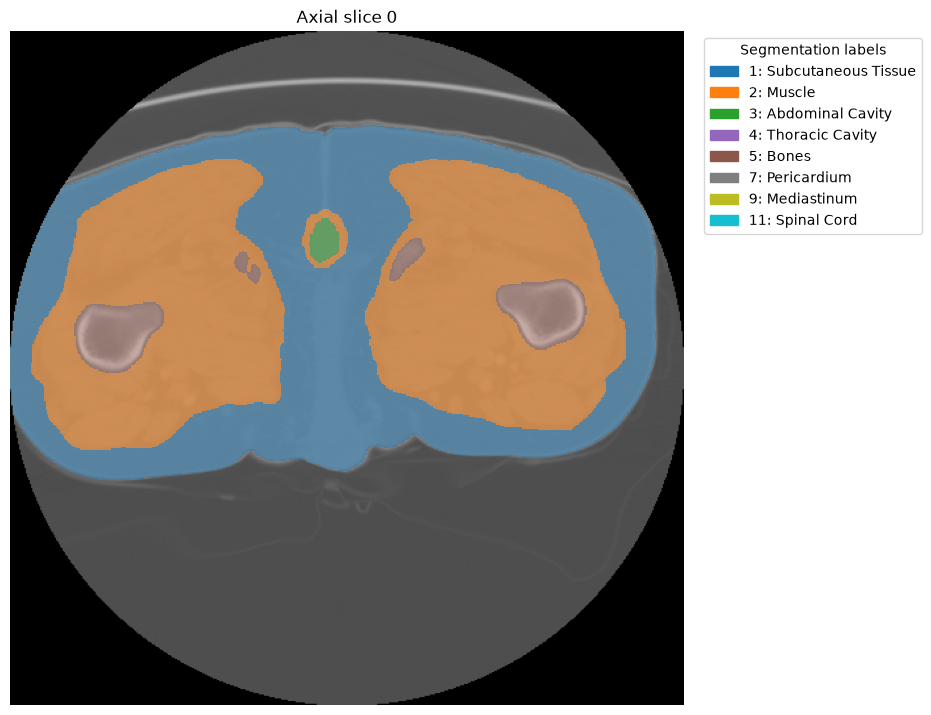

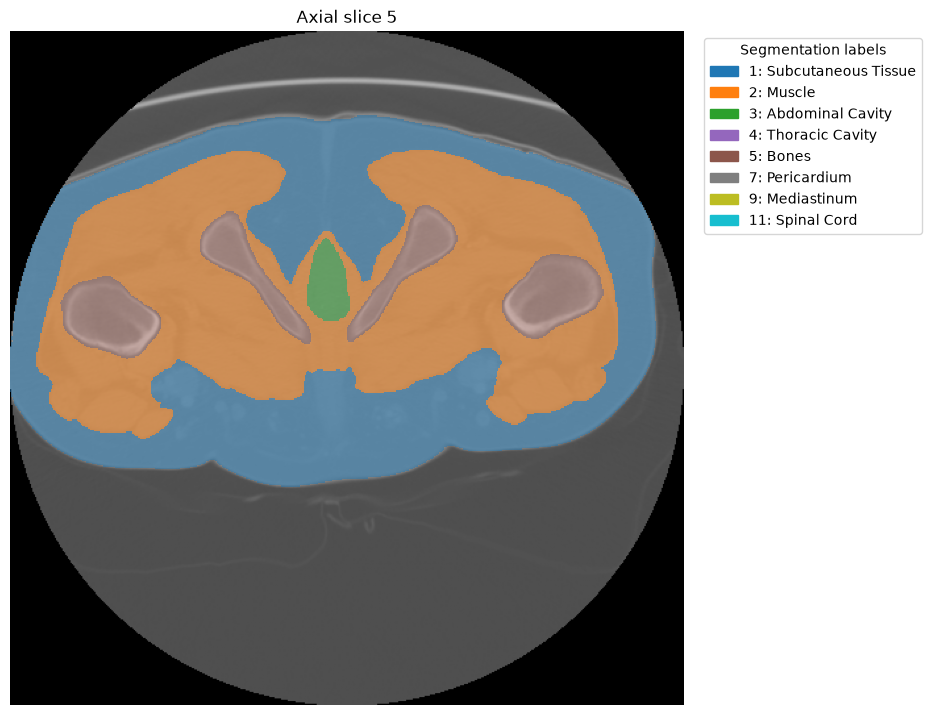

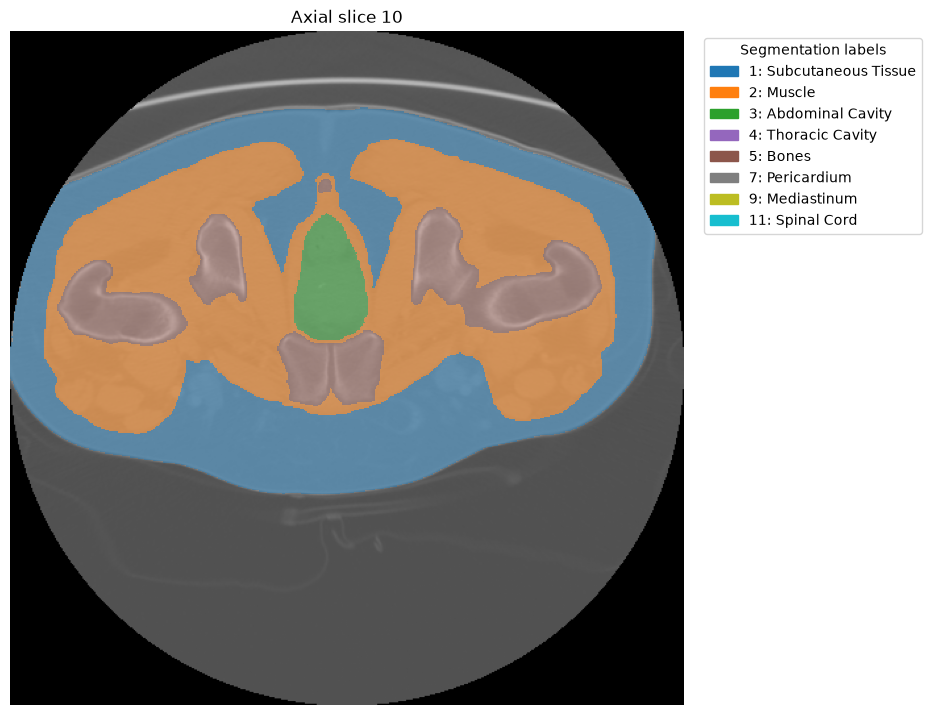

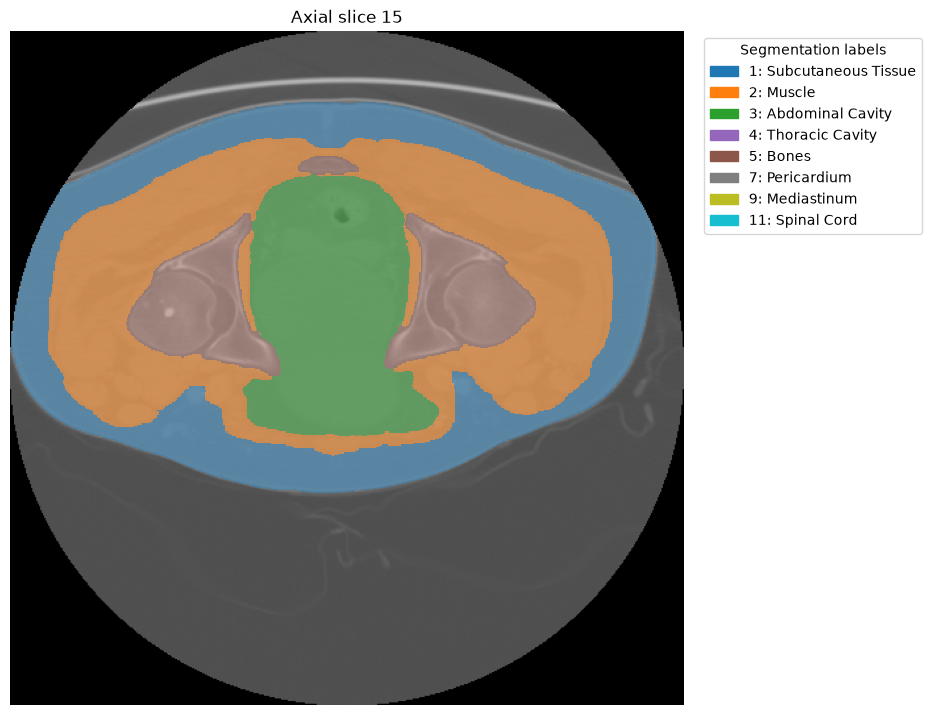

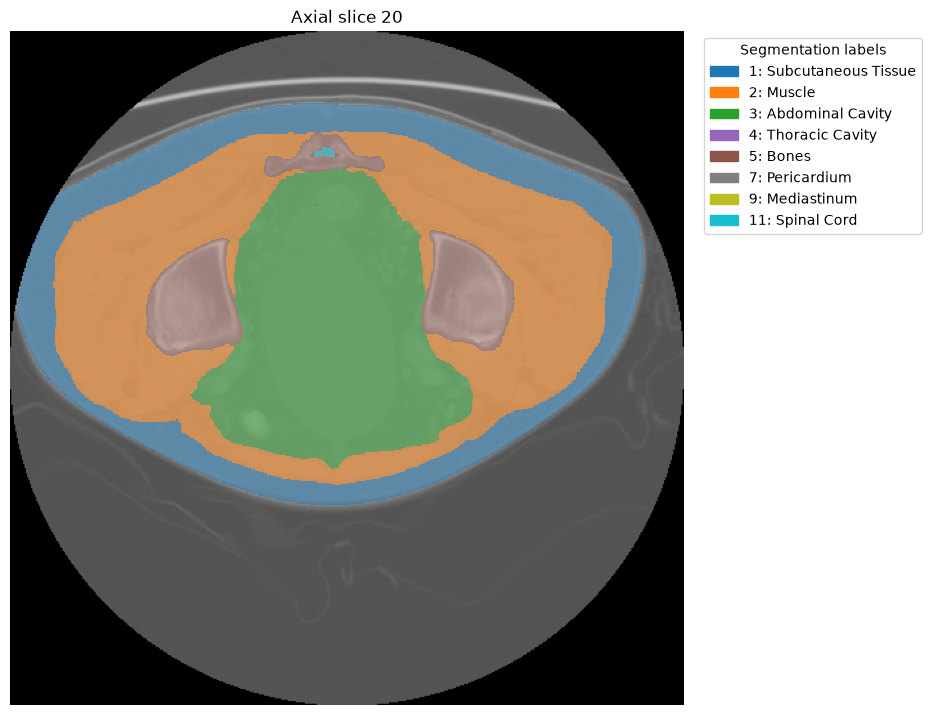

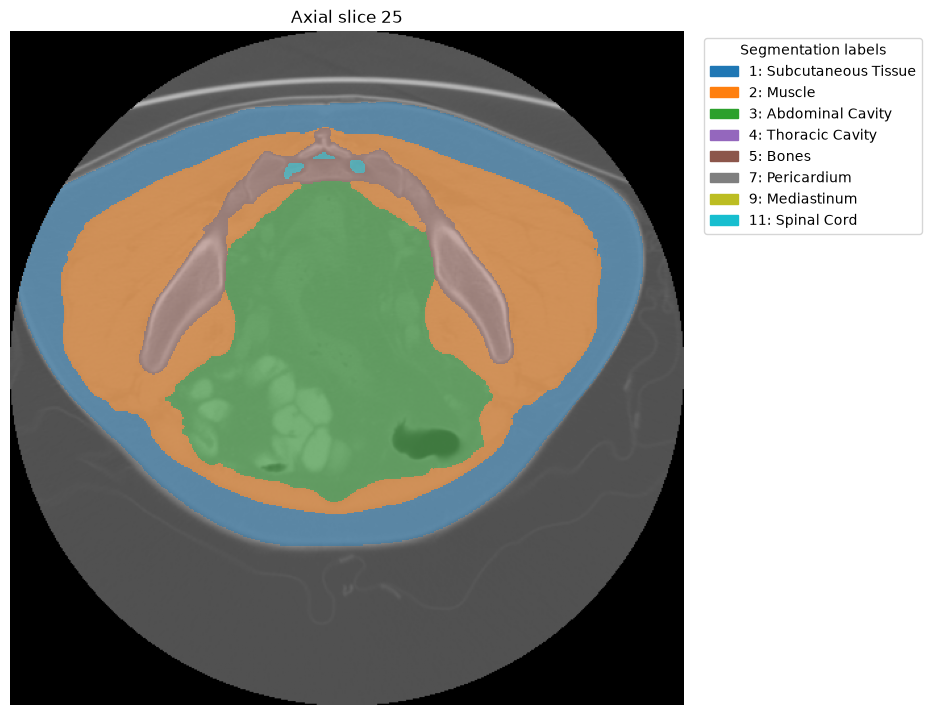

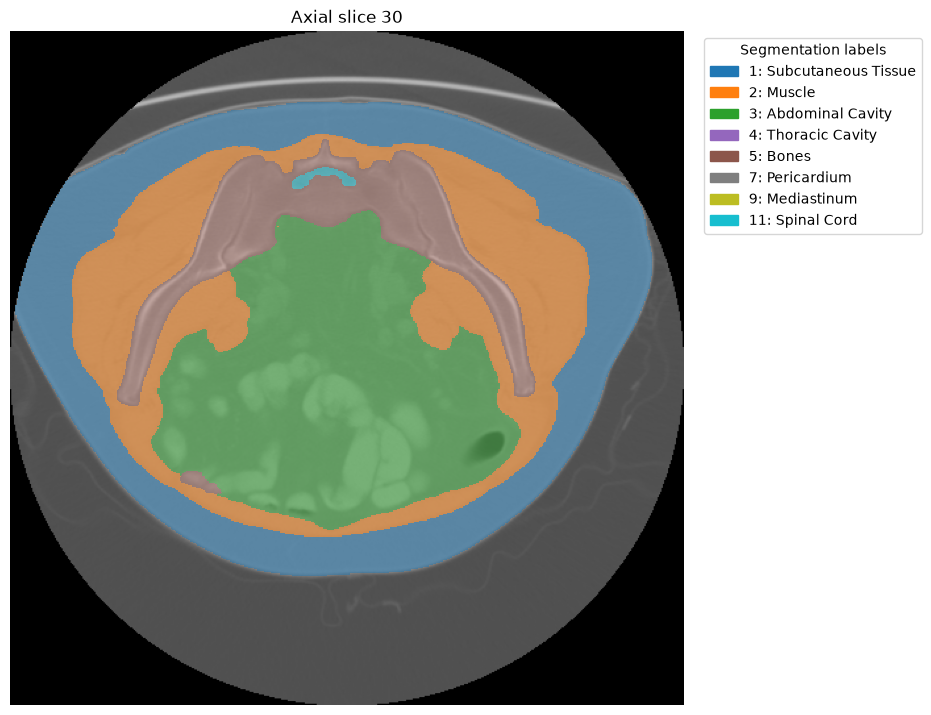

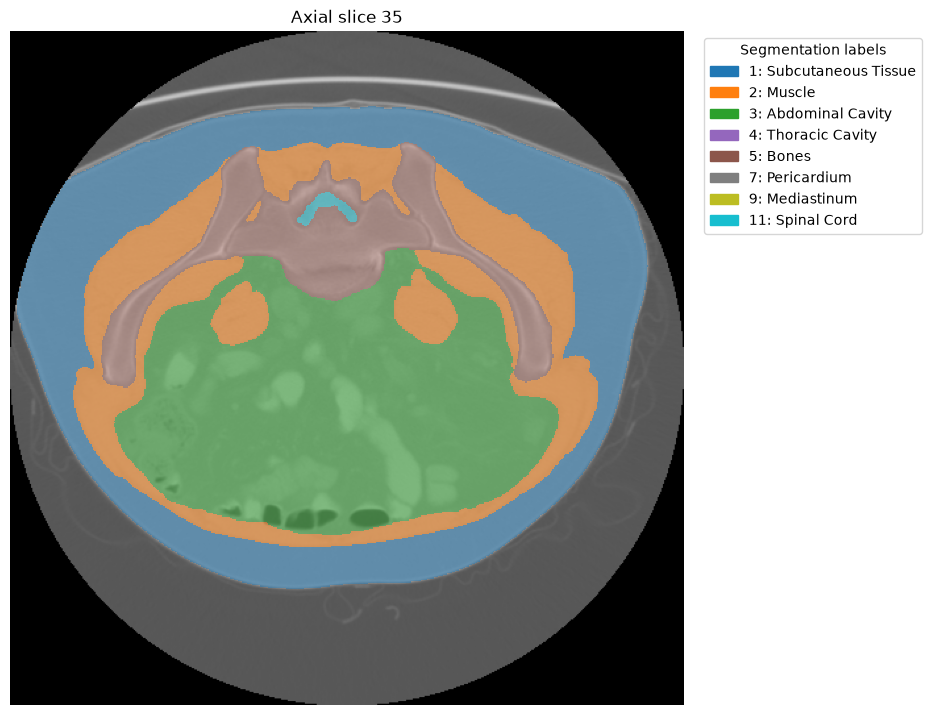

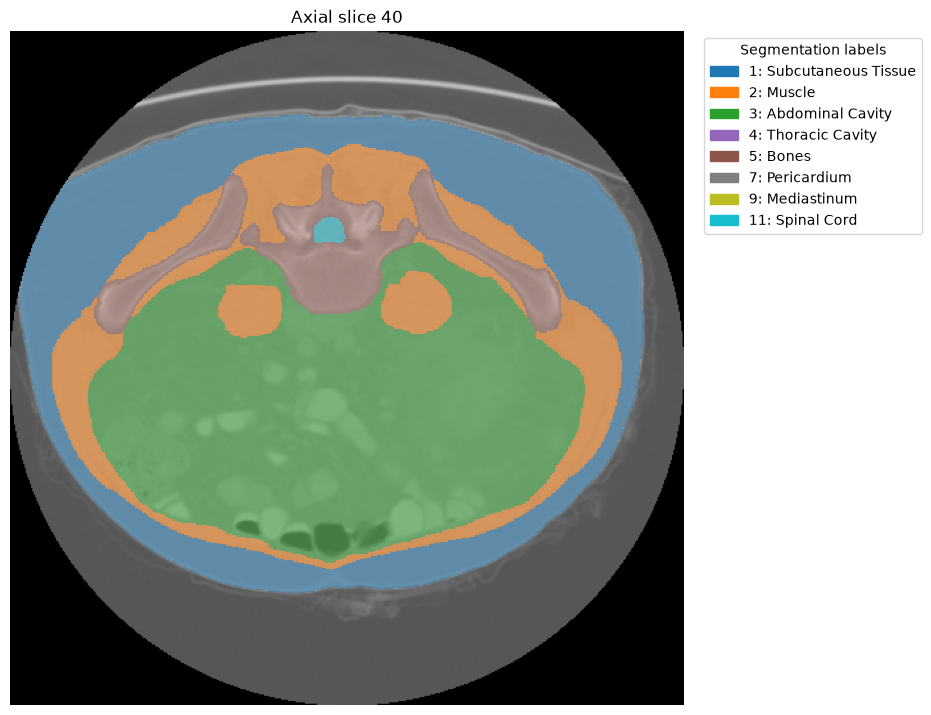

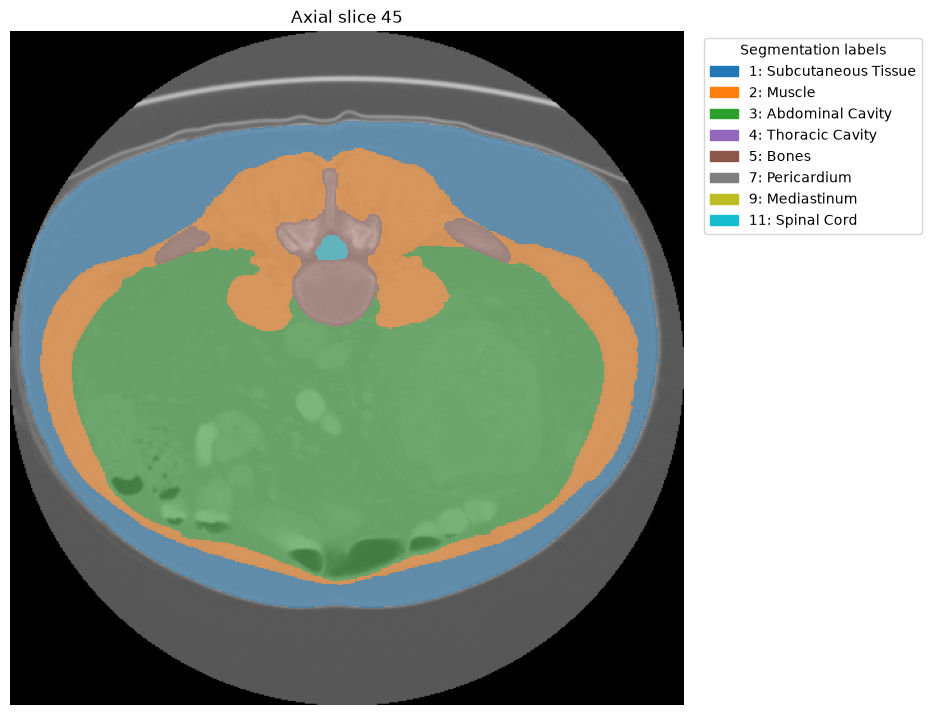

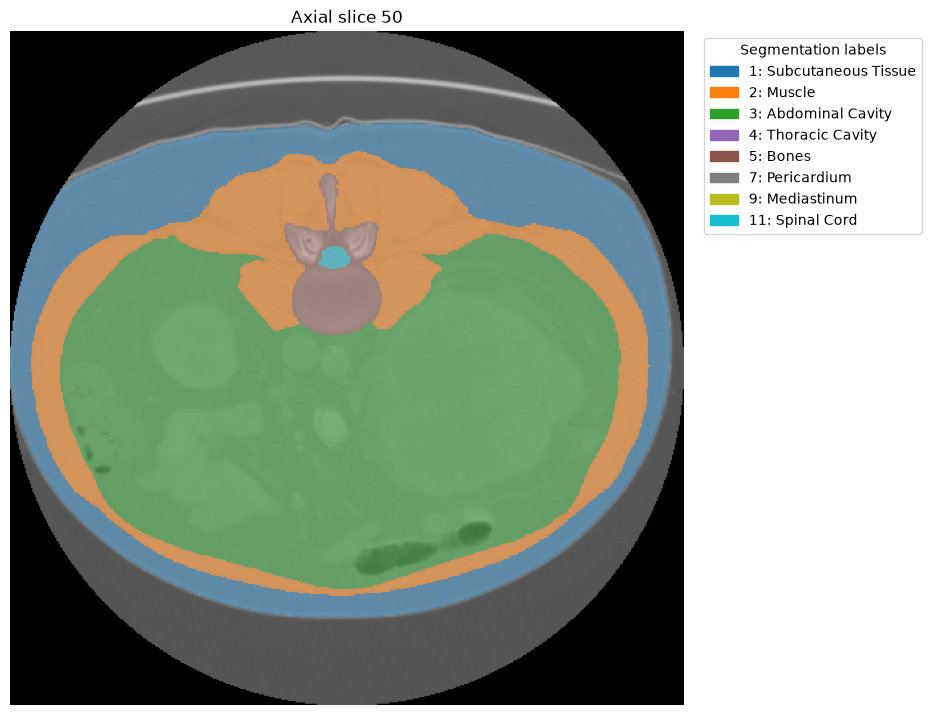

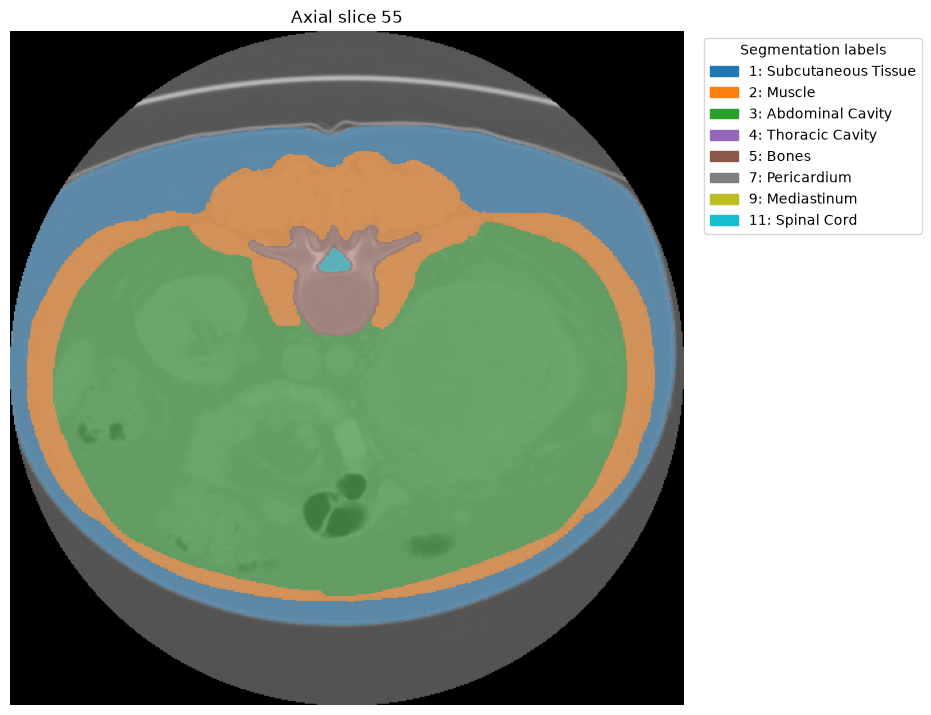

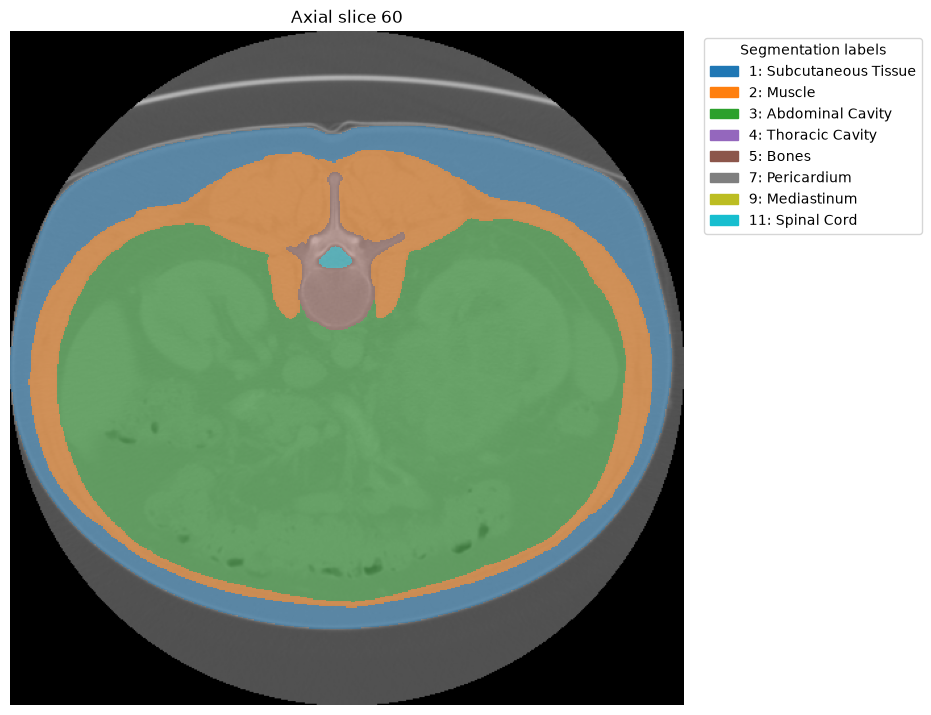

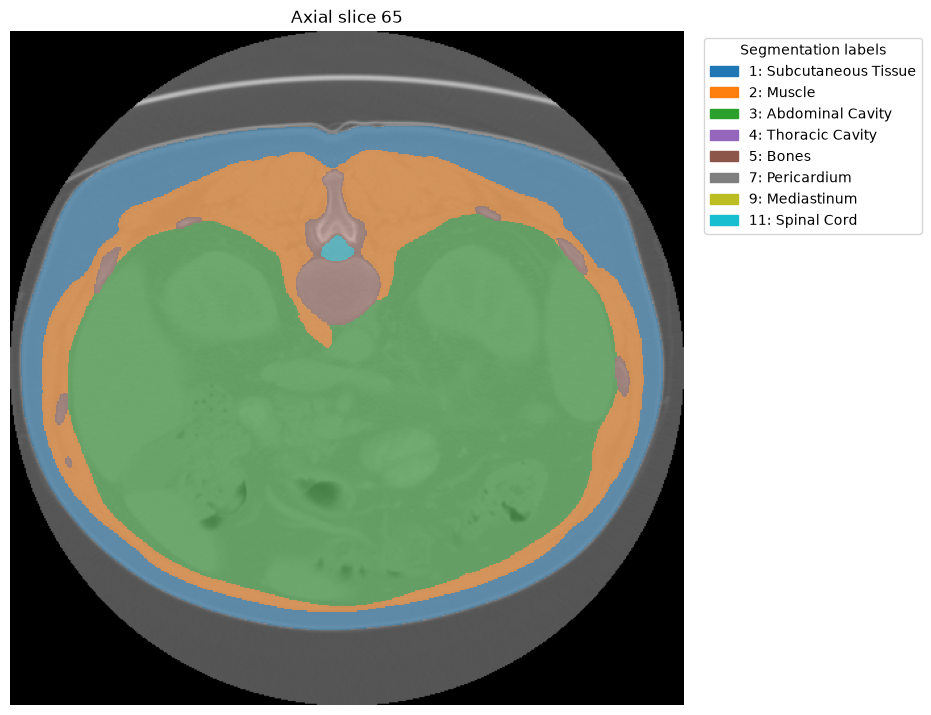

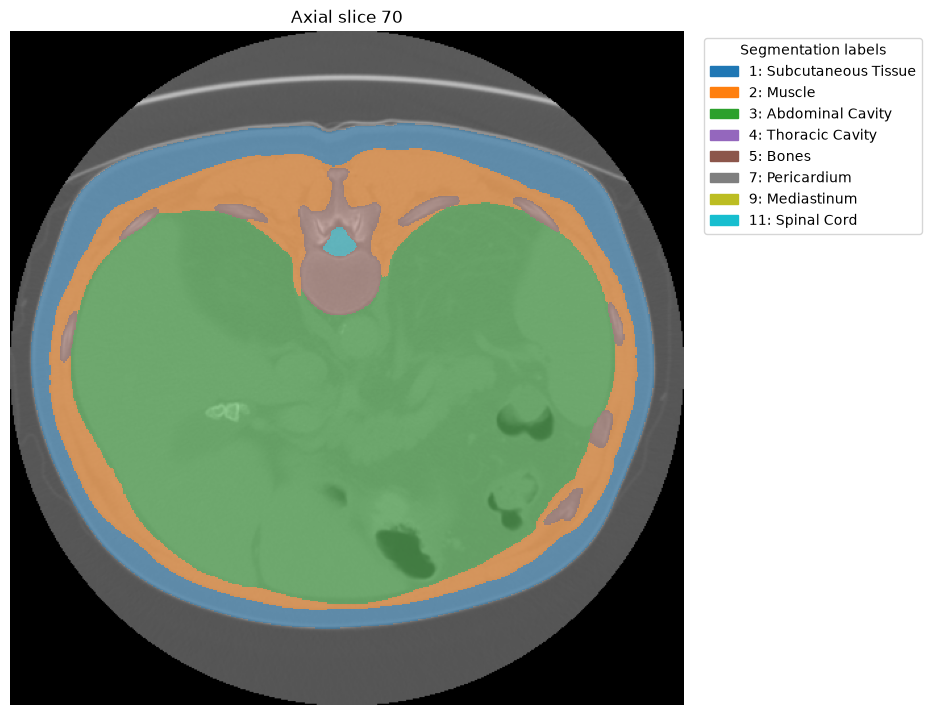

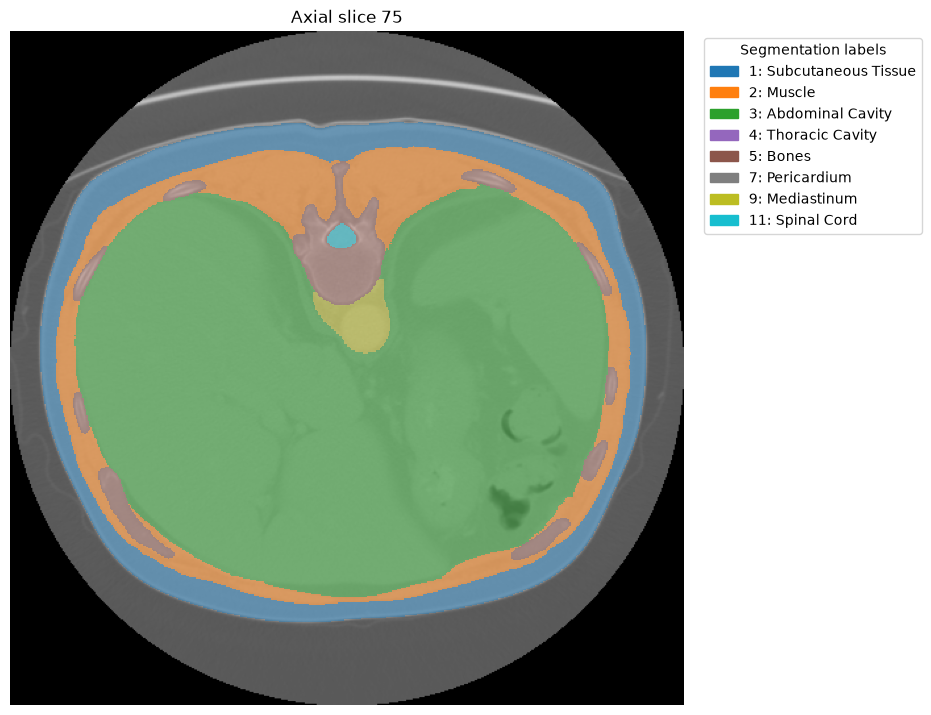

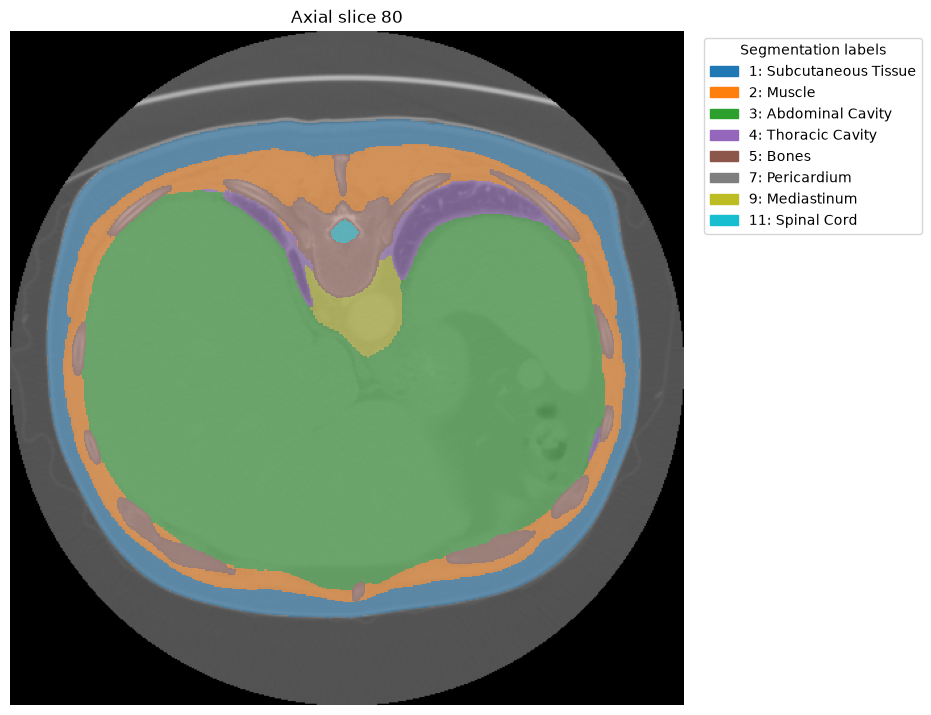

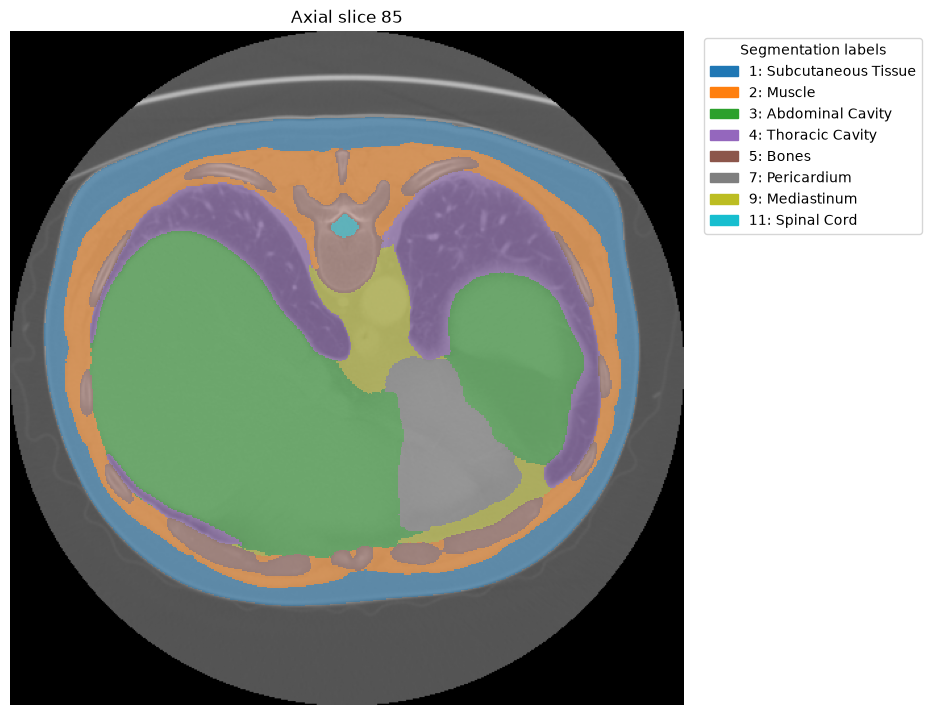

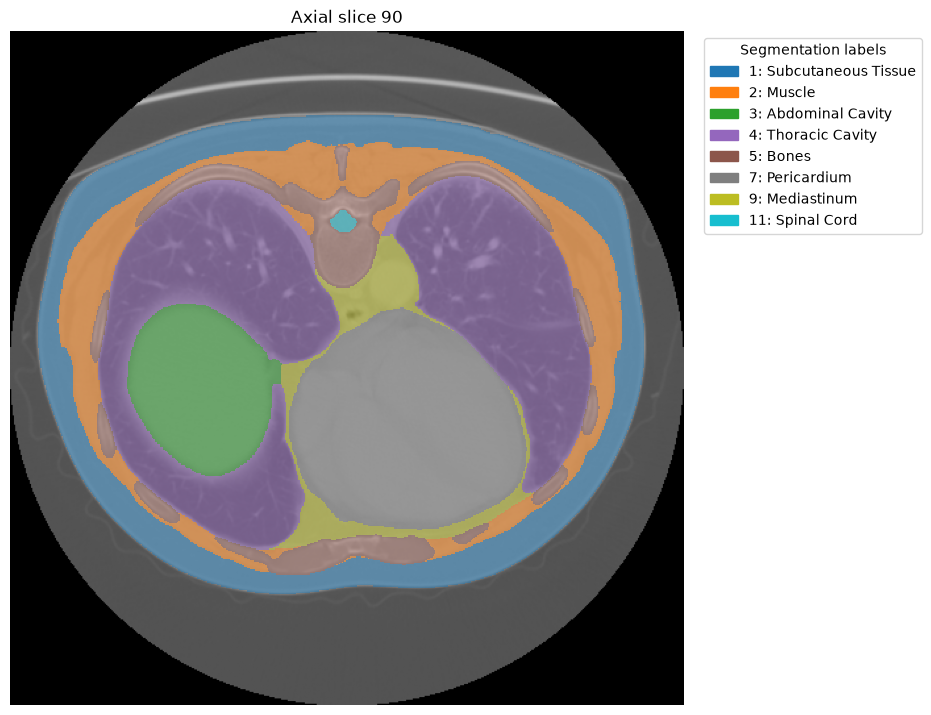

In [124]:
import matplotlib.patches as mpatches

# Get unique segmentation labels, excluding background (0)
# labels = np.unique(seg).astype(int)
# labels = labels[labels != 0]

label_mapping = {
0: "Background",
1: "Subcutaneous Tissue",
2: "Muscle",
3: "Abdominal Cavity",
4:"Thoracic Cavity",
5:"Bones",
6: "Parotid Glands",
7:"Pericardium",
8:"Breast Implant",
9:"Mediastinum",
10:"Brain",
11:"Spinal Cord",
12:"Thyroid Glands",
13:"Submandibular Glands"
}
# Keep only labels defined in label_mapping
valid_labels = list(label_mapping.keys())

# Set all other labels to background (0)
seg[~np.isin(seg, valid_labels)] = 0
# Only include labels actually present, excluding background
labels = np.unique(seg).astype(int)
labels = labels[labels != 0]

# Create a consistent colormap for all slices
cmap = plt.get_cmap("tab10", len(labels))

# Map each label to a colour
label_colors = {
    label: cmap(i) for i, label in enumerate(labels)
}

# Display every 10th slice
step = 5

for slice_idx in range(0, ct.shape[2], step):

    fig, ax = plt.subplots(figsize=(9, 8))

    ax.imshow(
        ct[:, :, slice_idx].T,
        cmap="gray",
        origin="lower"
    )

    # Overlay each label separately
    for label, color in label_colors.items():
        mask = np.ma.masked_where(
            seg[:, :, slice_idx].T != label,
            seg[:, :, slice_idx].T
        )

        ax.imshow(
            mask,
            cmap=plt.matplotlib.colors.ListedColormap([color]),
            alpha=0.5,
            origin="lower",
            interpolation="nearest"
        )

      # Named legend
    legend_handles = [
        mpatches.Patch(
            color=label_colors[label],
            label=f"{label}: {label_mapping[label]}"
        )
        for label in labels
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        title="Segmentation labels"
    )

    ax.set_title(f"Axial slice {slice_idx}")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

Label 0.0: 19231984 voxels
Label 1.0: 2893039 voxels
Label 2.0: 337981 voxels
Label 3.0: 2090403 voxels
Label 4.0: 88129 voxels


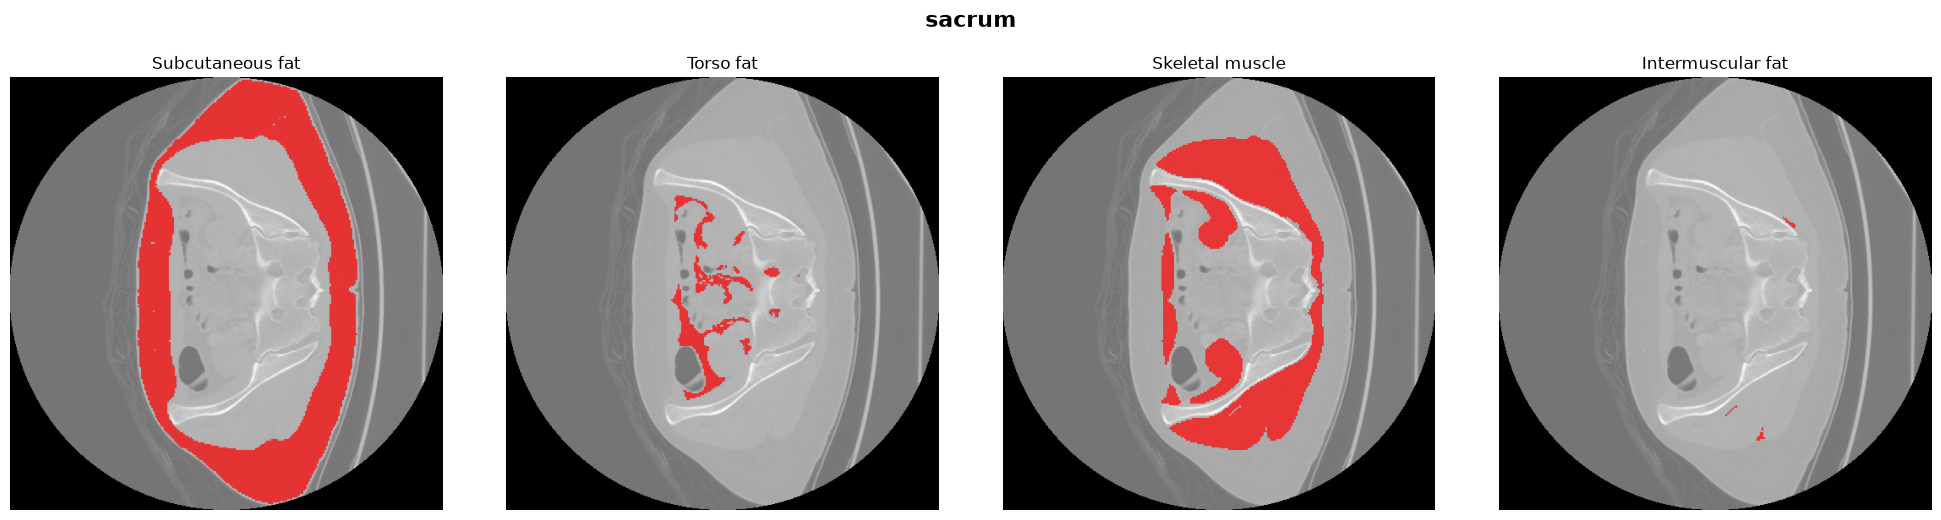

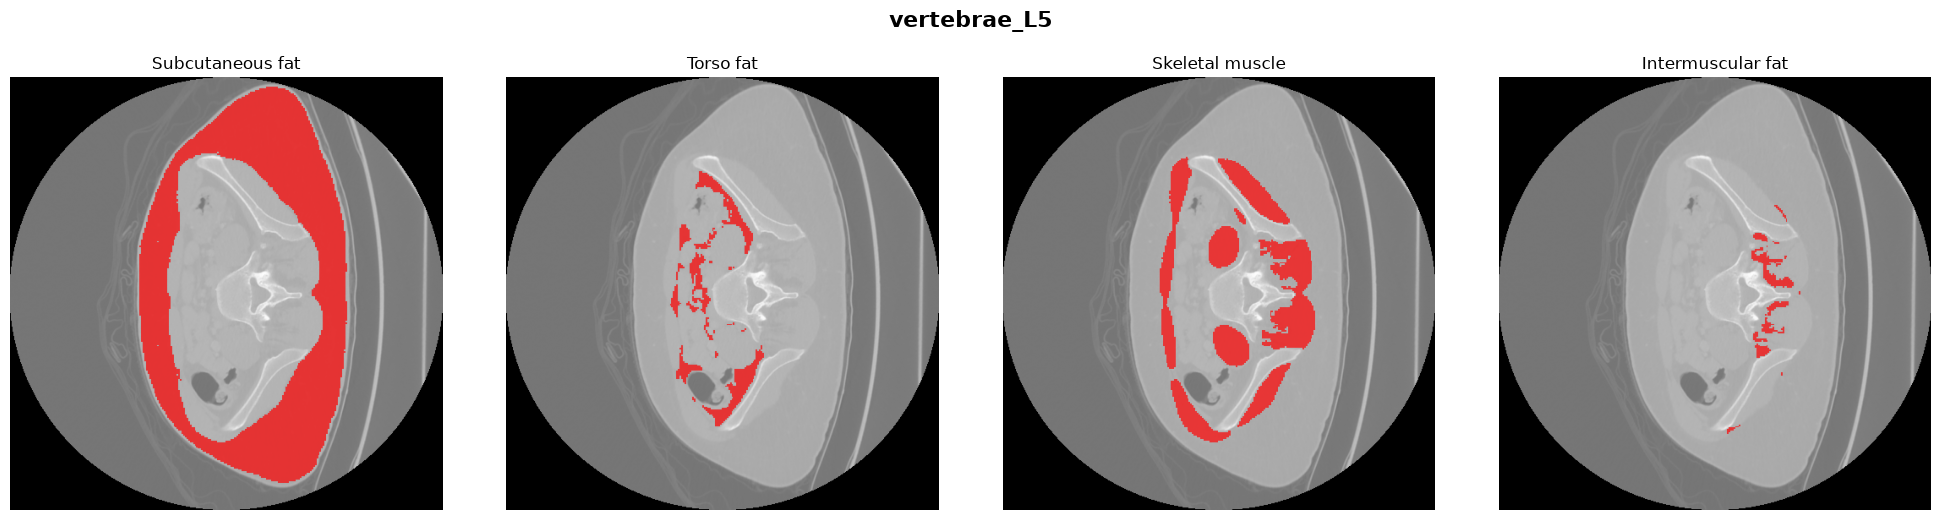

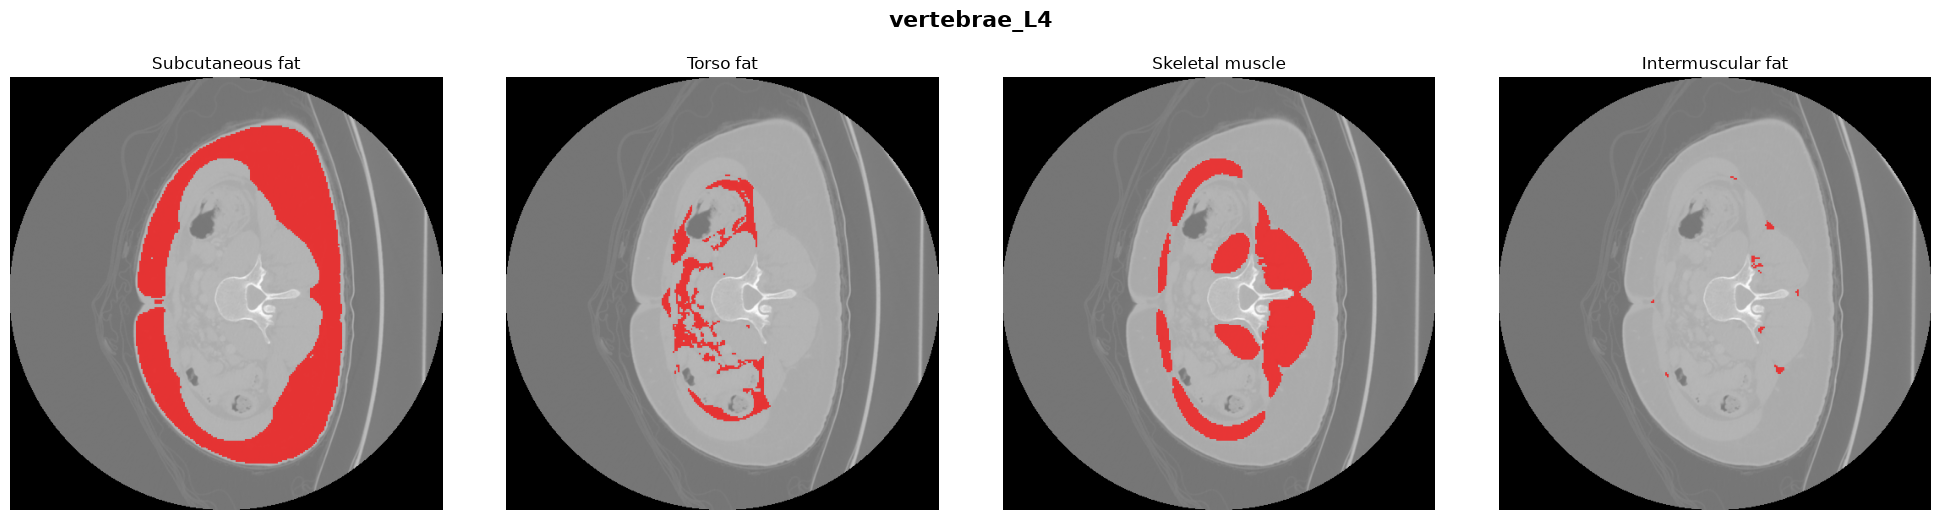

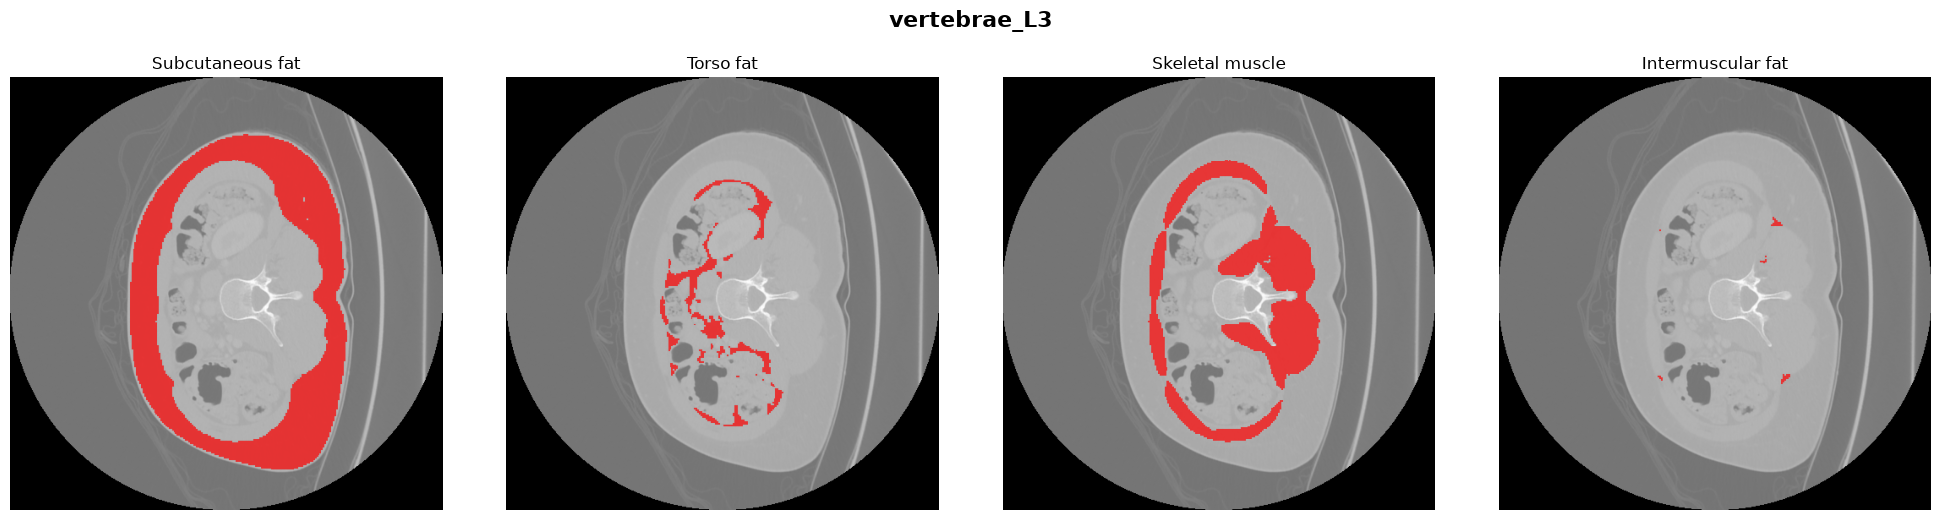

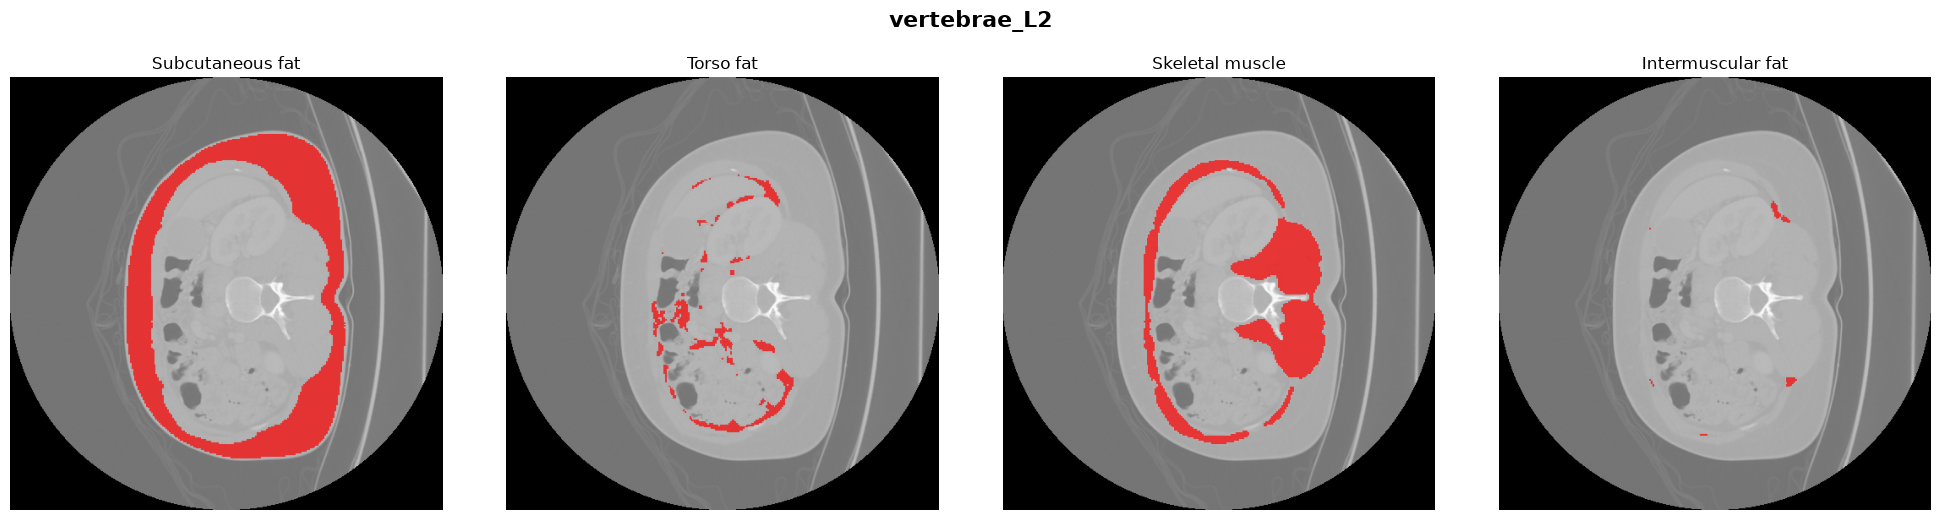

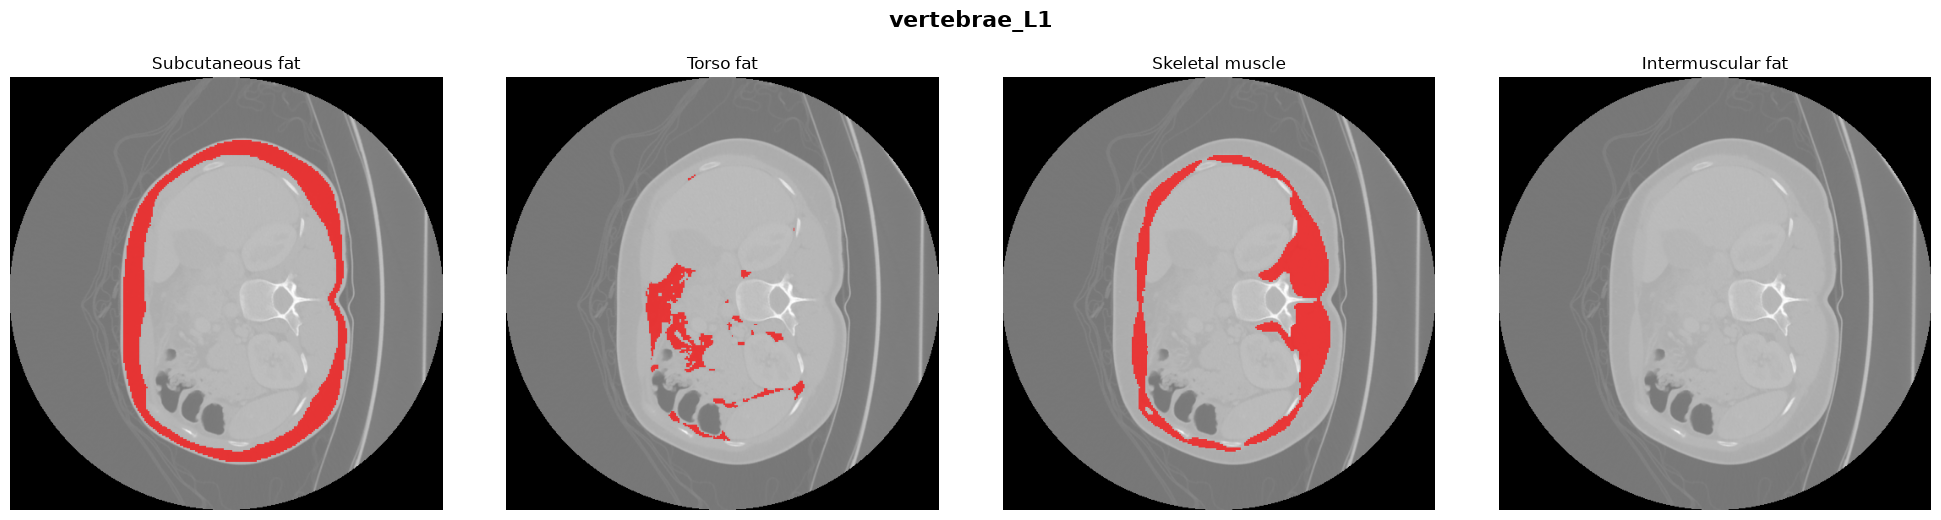

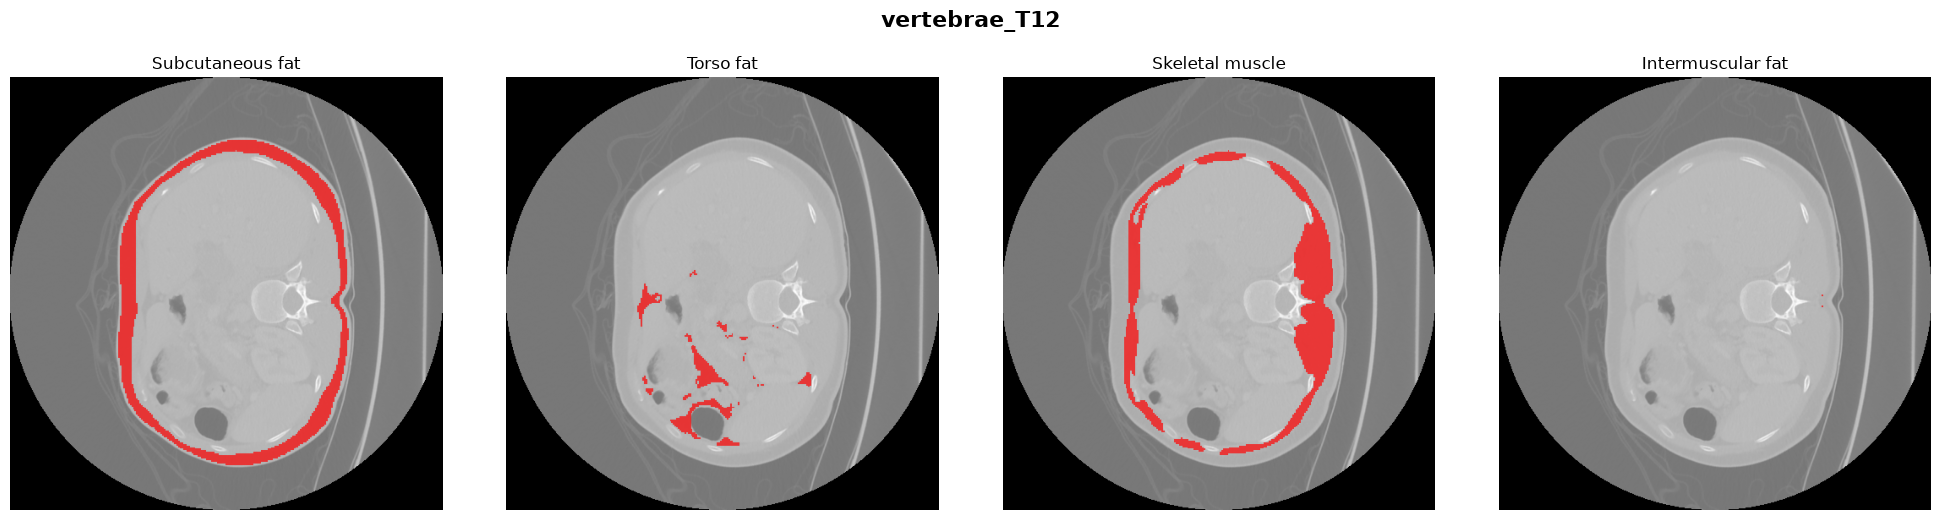

In [15]:
from pathlib import Path
tissue_file = Path(r"C:\Users\P095551\PycharmProjects\Body_comp\segmentator_output\case_000\tissues.nii.gz")
vertebrae_file = Path(r"C:\Users\P095551\PycharmProjects\Body_comp\segmentator_output\case_000\vertebrae.nii.gz")
ct_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_000\image.nii.gz"
 

%matplotlib inline
tissue_labels = {
    1: "Subcutaneous fat",
    2: "Torso fat",
    3: "Skeletal muscle",
    4: "Intermuscular fat"
}
vertebrae_labels = {
    25: "sacrum",
    27: "vertebrae_L5",
    28: "vertebrae_L4",
    29: "vertebrae_L3",
    30: "vertebrae_L2",
    31: "vertebrae_L1",
    32: "vertebrae_T12"
}


# Load NIfTI files
ct_nii = nib.load(ct_path)
# Get image arrays
ct = ct_nii.get_fdata()

# Load tissue segmentation
tissue_seg_nii = nib.load(str(tissue_file))
tissue_seg = tissue_seg_nii.get_fdata()
    # Select slice
labels, counts = np.unique(tissue_seg, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} voxels")
    
# Load vertrebrae segmentation
vert_seg_nii = nib.load(str(vertebrae_file))
vert_seg = vert_seg_nii.get_fdata()  



for label, name in vertebrae_labels.items():
    if label == 0:
        continue
        
    # Find slice with the largest vertebral cross-section
    slice_areas = np.sum(vert_seg == label, axis=(0, 1))
    
     # Skip empty segmentations
    if np.max(slice_areas) == 0:
        print(f" No segmentation found. Skipping.")
        continue
    
    
    max_area = np.max(slice_areas)
    
    # All slices with the maximum number of pixels
    max_slices = np.where(slice_areas == max_area)[0]
    
    # Take median slice
    slice_idx = int(max_slices[len(max_slices) // 2])
    #slice_idx = np.argmax(slice_areas)
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f"{name}", fontsize=16, fontweight="bold", y=1.03)
    
    for label, name in tissue_labels.items():
        if label == 0:
            continue
    
        mask = np.ma.masked_where(
            seg[:, :, slice_idx] != label,
            seg[:, :, slice_idx]
        )
    
        axes[label - 1].imshow(ct[:, :, slice_idx], cmap="gray")
        axes[label - 1].imshow(mask, cmap="autumn", alpha=0.7)
        axes[label - 1].set_title(name)
        axes[label - 1].axis("off")
    
    plt.tight_layout()
    plt.show()

In [98]:
if at_home == True:
    # Paths
    ct_path = r"C:\Users\paula\Downloads\SAROS_CT_IMAGES\case_000\image.nii.gz"
    seg_path = r"SAROS-Collection-NIfTI-files-v2_03-70-2024/SAROS-Collection-NIfTI-files-v2_03-70-2024/case_000/body-regions.nii.gz"
else:
    ct_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_002\image.nii.gz"
    seg_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\segmentation\SAROS-Collection-NIfTI-files-v2_03-70-2024\case_002\body-regions.nii.gz"


In [125]:
# Get voxel spacing in mm
spacing = ct_nii.header.get_zooms()

pixel_area_mm2 = spacing[0] * spacing[1]

print("Pixel area:", pixel_area_mm2, "mm²")

Pixel area: 0.61035156 mm²


In [126]:
#seg_path = r"SAROS-Collection-NIfTI-files-v2_03-70-2024/SAROS-Collection-NIfTI-files-v2_03-70-2024/case_002/body-regions.nii.gz"

# Load NIfTI files
ct_nii = nib.load(ct_path)
seg_nii_comp = nib.load(seg_path)

# Get image arrays
ct = ct_nii.get_fdata()
seg_comp = seg_nii_comp.get_fdata()

In [127]:
print("Shape:", seg_comp.shape)
print("Unique labels:", np.unique(seg_comp))
print("Nonzero voxels:", np.sum(seg_comp > 0))
print("Voxel spacing:", seg_nii_comp.header.get_zooms())

Shape: (512, 512, 95)
Unique labels: [  0.   1.   2.   3.   4.   5.   7.   9.  11. 255.]
Nonzero voxels: 22385788
Voxel spacing: (np.float32(0.78125), np.float32(0.78125), np.float32(5.0))


In [128]:
# Find slices containing at least one annotated voxel
annotated_slices = np.where(
    np.any(np.isin(seg_comp, [1, 2]), axis=(0, 1))
)[0]

print("Annotated slices:", annotated_slices)

Annotated slices: [ 0  5 10 15 20 25 30 35 40 45 50 55 60 65 70 75 80 85 90 94]


In [129]:
### find center slice of each vertebra
import pandas as pd
results = []
annotated_slices = np.where(
    np.any(np.isin(seg_comp, [1, 2]), axis=(0, 1))
)[0]

for file in sorted(folder.glob("vertebrae_*.nii.gz")):

    # Extract vertebra name
    vertebra = file.name.replace("vertebrae_", "").replace(".nii.gz", "")

    # Load vertebra segmentation
    vertebra_nii = nib.load(str(file))
    vertebra_seg = vertebra_nii.get_fdata()

    # Find slice with the largest vertebral cross-section
    slice_areas = np.sum(vertebra_seg > 0, axis=(0, 1))

     # Skip empty segmentations
    if np.max(slice_areas) == 0:
        print(f"{vertebra}: No segmentation found. Skipping.")
        continue

    max_area = np.max(slice_areas)

    # All slices with the maximum number of pixels
    max_slices = np.where(slice_areas == max_area)[0]

    # Take median slice
    slice_idx = int(max_slices[len(max_slices) // 2])
    #slice_idx = np.argmax(slice_areas)


    # Find nearest annotated body-composition slice
    nearest_annotated = annotated_slices[
    np.argmin(np.abs(annotated_slices - slice_idx))
    ]
    # Calculate body composition areas at this slice
    body_slice = seg_comp[:, :, nearest_annotated]


    print(f"{vertebra}: vertebra slice {slice_idx}, "
      f"body composition slice {nearest_annotated}")
    slice_difference = abs(nearest_annotated - slice_idx)
    distance_mm = slice_difference * spacing[2]

    n_fat = np.sum(body_slice == 1)
    n_muscle = np.sum(body_slice == 2)


    # Convert pixel count to cm²
    area_subcutaneous = n_fat * pixel_area_mm2 / 100
    area_muscle = n_muscle * pixel_area_mm2 / 100

    results.append({
        "Vertebra": vertebra,
        "Slice": slice_idx,
        "Selected slice": nearest_annotated,
        "Slice difference": slice_difference,
        "Distance (mm)": distance_mm,
        "Subcutaneous Tissue (mm²)": area_subcutaneous,
        "Muscle (mm²)": area_muscle
    })

df_landmarks = pd.DataFrame(results)

print(df_landmarks)

L1: vertebra slice 70, body composition slice 70
L2: vertebra slice 64, body composition slice 65
L3: vertebra slice 59, body composition slice 60
L4: vertebra slice 53, body composition slice 55
L5: vertebra slice 48, body composition slice 50
T1: No segmentation found. Skipping.
T10: vertebra slice 87, body composition slice 85
T11: vertebra slice 80, body composition slice 80
T12: vertebra slice 75, body composition slice 75
T2: No segmentation found. Skipping.
T3: No segmentation found. Skipping.
T4: No segmentation found. Skipping.
T5: No segmentation found. Skipping.
T6: No segmentation found. Skipping.
T7: vertebra slice 94, body composition slice 94
T8: vertebra slice 94, body composition slice 94
T9: vertebra slice 93, body composition slice 94
   Vertebra  Slice  Selected slice  Slice difference  Distance (mm)  \
0        L1     70              70                 0            0.0   
1        L2     64              65                 1            5.0   
2        L3     59     

In [130]:
df_landmarks.columns

Index(['Vertebra', 'Slice', 'Selected slice', 'Slice difference',
       'Distance (mm)', 'Subcutaneous Tissue (mm²)', 'Muscle (mm²)'],
      dtype='str')

In [131]:
import pandas as pd
results = []

# Every 5th slice is annotated
for slice_idx in range(0, seg_comp.shape[2], 5):

    slice_seg = seg_comp[:, :, slice_idx]

    # Count pixels belonging to each label
    n_subcutaneous = np.sum(slice_seg == 1)
    n_muscle = np.sum(slice_seg == 2)

    # Convert pixel count to cm²
    area_subcutaneous = n_subcutaneous * pixel_area_mm2 / 100
    area_muscle = n_muscle * pixel_area_mm2 / 100

    results.append({
        "slice": slice_idx,
        "Subcutaneous Tissue (cm2)": area_subcutaneous,
        "Muscle (cm2)": area_muscle
    })

# Convert to DataFrame
df = pd.DataFrame(results)

print(df.head())

   slice  Subcutaneous Tissue (cm2)  Muscle (cm2)
0      0                 292.480469    342.950439
1      5                 295.733643    311.706543
2     10                 271.307373    297.113037
3     15                 195.782471    261.572266
4     20                 143.585205    262.689209


In [132]:
# Map selected body-composition slice to vertebral level
vertebra_mapping = dict(zip(
    df_landmarks["Selected slice"],
    df_landmarks["Vertebra"]
))

# Add vertebra column
df["Vertebra"] = df["slice"].map(vertebra_mapping)

In [81]:
from totalsegmentator.python_api import totalsegmentator
from pathlib import Path

#ct_path = Path( r"C:\Users\paula\Downloads\SAROS_CT_IMAGES\case_002\image.nii.gz")
output_dir = Path("segmentator_output/case_160")

output_dir.mkdir(parents=True, exist_ok=True)

vertebrae = [
    f"vertebrae_{level}"
    for level in [
        "T1", "T2", "T3", "T4", "T5", "T6",
        "T7", "T8", "T9", "T10", "T11", "T12",
        "L1", "L2", "L3", "L4", "L5"
    ]
]

totalsegmentator(
    input=str(ct_path),
    output=str(output_dir),
    task="total",
    roi_subset=vertebrae,
    device="cpu",
    fast=True
)


If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024

Using 'fast' option: resampling to lower resolution (3mm)
Generating rough segmentation for cropping...
Resampling...
  Resampled in 0.09s
Predicting...


100%|██████████| 8/8 [00:03<00:00,  2.14it/s]


  Predicted in 35.04s
Resampling...
  Resampled in 0.35s
  cropping from (512, 512, 95) to (182, 189, 64)
Resampling...
  Resampled in 0.03s
Predicting...


100%|██████████| 1/1 [00:03<00:00,  3.14s/it]


  Predicted in 26.80s
Resampling...
  Resampled in 0.03s
Saving segmentations...
  Saved in 25.60s


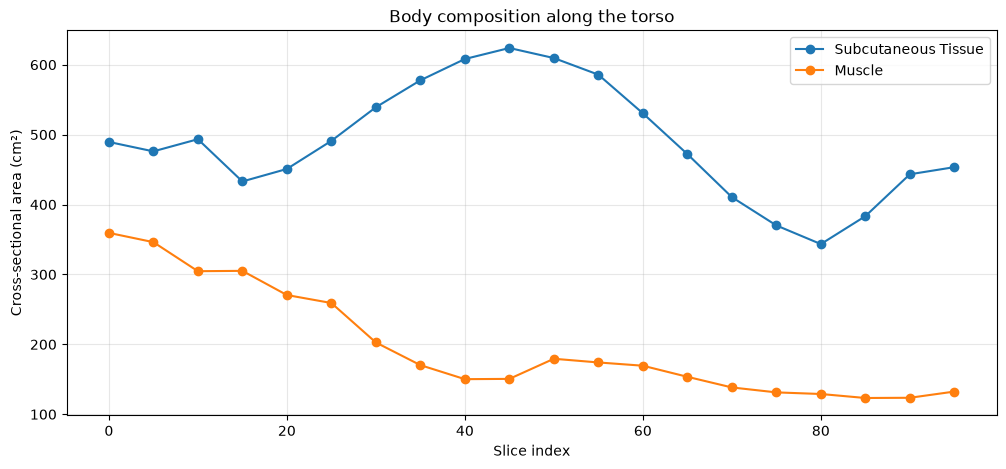

In [107]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["slice"],
    df["Subcutaneous Tissue (cm2)"],
    marker="o",
    label="Subcutaneous Tissue"
)

plt.plot(
    df["slice"],
    df["Muscle (cm2)"],
    marker="o",
    label="Muscle"
)

plt.xlabel("Slice index")
plt.ylabel("Cross-sectional area (cm²)")
plt.title("Body composition along the torso")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

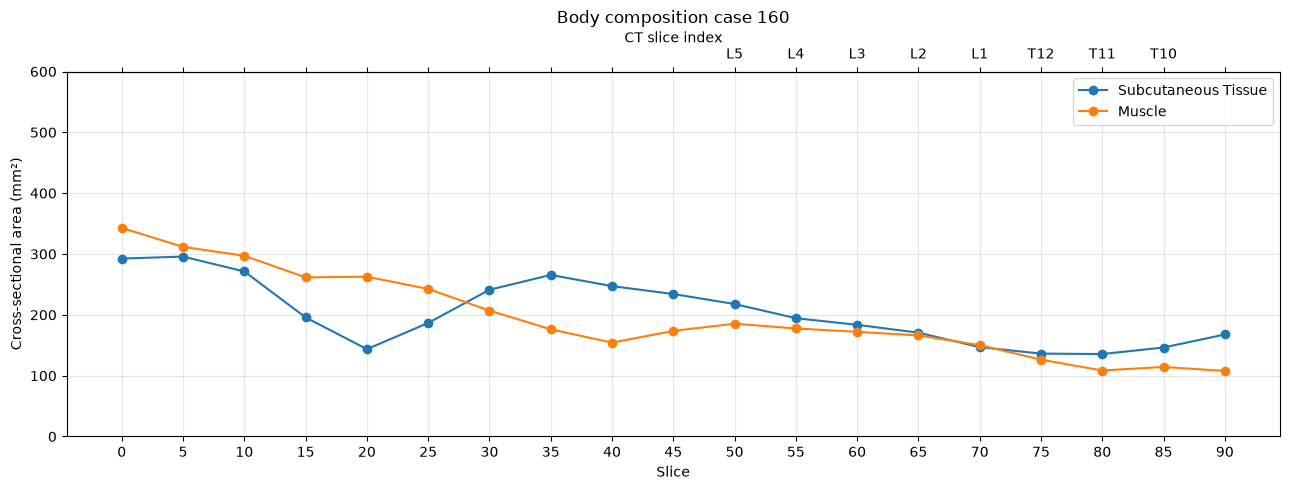

In [133]:


fig, ax = plt.subplots(figsize=(13, 5))

x = np.arange(len(df))

# Plot tissue areas
ax.plot(
    x,
    df["Subcutaneous Tissue (cm2)"],
    marker="o",
    label="Subcutaneous Tissue"
)

ax.plot(
    x,
    df["Muscle (cm2)"],
    marker="o",
    label="Muscle"
)

# Bottom axis: vertebral levels
ax.set_xticks(x)
ax.set_xticklabels(df["slice"])
ax.set_ylim(0, 600)
ax.set_xlabel("Slice")
ax.set_ylabel("Cross-sectional area (mm²)")
ax.set_title("Body composition case 160")

# Top axis: slice indices
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(x)
ax_top.set_xticklabels(
    df["Vertebra"].fillna("")
)
ax_top.set_xlabel("CT slice index")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Sort by selected slice index
df_landmarks = df_landmarks.sort_values("Selected slice").reset_index(drop=True)


fig, ax = plt.subplots(figsize=(13, 5))

x = np.arange(len(df_landmarks))

# Plot tissue areas
ax.plot(
    x,
    df_landmarks["Subcutaneous Tissue (mm²)"],
    marker="o",
    label="Subcutaneous Tissue"
)

ax.plot(
    x,
    df_landmarks["Muscle (mm²)"],
    marker="o",
    label="Muscle"
)

# Bottom axis: vertebral levels
ax.set_xticks(x)
ax.set_xticklabels(df_landmarks["Vertebra"])

ax.set_xlabel("Vertebral level")
ax.set_ylabel("Cross-sectional area (mm²)")
ax.set_title("Body composition along the torso")

# Top axis: slice indices
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(x)
ax_top.set_xticklabels(df_landmarks["Selected slice"])
ax_top.set_xlabel("CT slice index")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()